In [8]:
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import numpy as np
import torch
from frozendict import frozendict

from dream_robot.policies.verne import rollouts, vae
from dream_robot.policies.verne.data import canvas, load_cameras, load_table
from dream_robot.policies.verne.run import RUNS, split

# Verne, step 03: VAE latents, what changed and how shapes flow

The results (VAE training, rollouts, scores): `03_vae_latents.ipynb` (T1-wide, 3 training seeds × 50: 112/150 at n_exec 8 and 16, step 02 29 and 14; every seed finds the cube).

One box opened: the input. The canvas no longer goes to the video transformer as pixel patches; a small frozen VAE (`vae.py`) turns it into a 4 × 16 × 32 latent grid first, and the patches are 2 × 2 squares of that grid. This notebook follows one canvas through: what the VAE keeps, the tokens it makes, and what the policy then looks at. No training here: the VAE and the policy are loaded from the step 03 runs (T1-wide, training seed 0).


In [9]:
NAME = 'pick_place_cube_wide_n100'
state, action, episode = load_table(NAME)  # [N, 8], [N, 8], [N]
data = frozendict(
    state=state, action=action, episode=episode, latent=vae.load_latents(NAME, vae.WEIGHTS)
)  # latent [N, 4, 16, 32] float16, encoded once
cams = frozendict(zip(('top', 'wrist'), load_cameras(NAME)))  # [N, 3, 128, 128] uint8 each
split_ids = frozendict(zip(('train', 'val'), split('t1-wide')))
print(f'{data['latent'].shape=}  {cams['top'].shape=}  val demos {split_ids["val"]}')

data['latent'].shape=(22409, 4, 16, 32)  cams['top'].shape=(22409, 3, 128, 128)  val demos [82 36 20  5 93 16 94 52 72 90]


In [10]:
enc = vae.load(vae.WEIGHTS)  # frozen
net = rollouts.load(torch.load(RUNS / '03_vae_latents/t1-wide/seed0/weights.pt'))
for name, m in (('VAE', enc), ('  of it, encoder', enc.enc), ('policy', net)):
    print(f'{name:16s} {sum(p.numel() for p in m.parameters()) / 1e6:.2f}M params')

VAE              1.88M params
  of it, encoder 1.22M params
policy           3.49M params


### 1. the eyes, part 0: a canvas becomes a latent grid

Two moments of one held-out demo: its first frame, and the step where the expert first commands close.


In [11]:
ep = split_ids['val'][0]
rows = np.flatnonzero(data['episode'] == ep)  # this demo's frames in the table
grasp = rows[np.argmax(data['action'][rows, 7] < 0.5)]  # first commanded close
moments = {'start': rows[0], 'grasp': grasp}
idx = list(moments.values())
x = torch.from_numpy(canvas(cams['top'][idx], cams['wrist'][idx])).cuda().float() / 127.5 - 1
print(f'demo {ep}: {moments}, x {tuple(x.shape)} in [-1, 1]')

demo 82: {'start': np.int64(18401), 'grasp': np.int64(18500)}, x (2, 3, 128, 256) in [-1, 1]


Through the encoder (`enc.enc` in `vae.py`), layer by layer. The residual blocks widen the channels 32 → 64 → 128; each stride-2 conv halves the height and width; the head gives 8 channels = 4 means + 4 log-variances.


In [12]:
h = x
with torch.no_grad():
    for layer in enc.enc:
        h = layer(h)
        kind = type(layer).__name__
        if kind == 'Conv2d' and layer.stride == (2, 2):
            kind = 'Conv2d /2'
        print(f'{kind:10s} -> {tuple(h.shape)}')

Conv2d     -> (2, 32, 128, 256)
ResBlock   -> (2, 64, 128, 256)
Conv2d /2  -> (2, 64, 64, 128)
ResBlock   -> (2, 128, 64, 128)
Conv2d /2  -> (2, 128, 32, 64)
ResBlock   -> (2, 128, 32, 64)
Conv2d /2  -> (2, 128, 16, 32)
ResBlock   -> (2, 128, 16, 32)
RMSNorm    -> (2, 128, 16, 32)
SiLU       -> (2, 128, 16, 32)
Conv2d     -> (2, 8, 16, 32)


In [13]:
print(f'canvas numbers: {3 * 128 * 256=}')
print(f'latent numbers: {4 * 16 * 32=}  (the mean; the log-variance is only used in training)')
print(f'{3 * 128 * 256 / (4 * 16 * 32)=}')

canvas numbers: 3 * 128 * 256=98304
latent numbers: 4 * 16 * 32=2048  (the mean; the log-variance is only used in training)
3 * 128 * 256 / (4 * 16 * 32)=48.0


**Three halvings: 128 × 256 → 16 × 32, so one latent cell stands for an 8 × 8 pixel square, and the canvas's 98,304 numbers become 2,048 (48× fewer).** The encoder is 1.22M of the VAE's 1.88M parameters, a third of the policy's size, and it runs once per replan at rollout.


The 4 latent channels of each moment (`enc.encode`: the mean, normalised to mean 0, std 1 per channel), and what the decoder draws back from them:


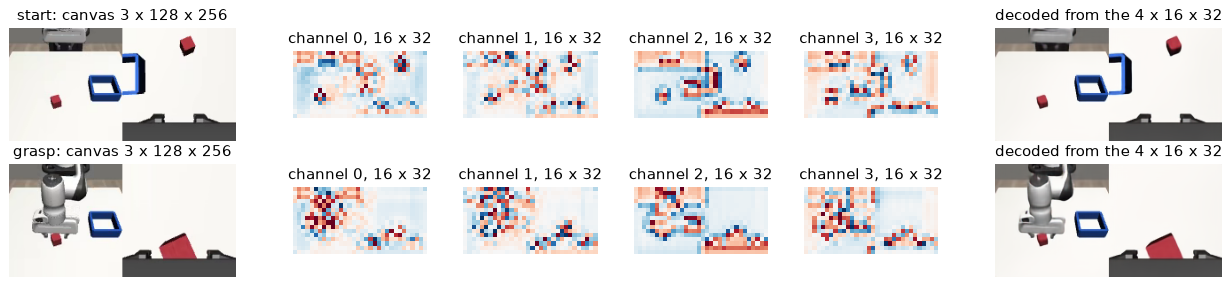

In [14]:
with torch.no_grad():
    z = enc.encode(x)  # [2, 4, 16, 32]
    back = enc.dec(z * enc.z_std[:, None, None] + enc.z_mean[:, None, None]).clamp(-1, 1)
fig, axs = plt.subplots(2, 6, figsize=(18, 3.6), gridspec_kw={'width_ratios': [2, 1, 1, 1, 1, 2]})
for r, name in enumerate(moments):
    axs[r, 0].imshow((x[r].permute(1, 2, 0).cpu() + 1) / 2)
    axs[r, 0].set_title(f'{name}: canvas 3 x 128 x 256')
    for c in range(4):
        axs[r, 1 + c].imshow(z[r, c].cpu(), cmap='RdBu_r', vmin=-3, vmax=3)
        axs[r, 1 + c].set_title(f'channel {c}, 16 x 32')
    axs[r, 5].imshow((back[r].permute(1, 2, 0).cpu() + 1) / 2)
    axs[r, 5].set_title('decoded from the 4 x 16 x 32')
for ax in axs.flat:
    ax.axis('off')

**The white table is close to 0 in every channel; the numbers sit on the things: the bin, the cube, the arm, and in the wrist half the gripper base and whatever is in front of it.** At the start the far cube is a small dark spot a cell or two wide; at the grasp the arm fills the top half's left side and the cube is a large patch in the wrist half. Decoded back, cube and bin come out sharp, the gripper a little soft. Each channel isn't a clean "cube detector": all four mix edges and colours, and the decoder needs all four to redraw.


### 2. the eyes, part 1: the latent grid becomes 129 tokens

`see` in `model.py`: the 4 × 16 × 32 latent is cut into 2 × 2 squares, 8 × 16 = 128 of them, each 4 channels × 2 × 2 = 16 numbers, and one linear layer (`patch_in`) takes each to 256. The joints are token 0, as before. A 2 × 2 latent square stands for the same 16 × 16 pixel square a step 02 patch was, so the token grid lines up with step 02's exactly; only what's in each token changed.


In [ ]:
from einops import rearrange

s = torch.from_numpy(
    (data['state'][idx] - data['state'][np.isin(data['episode'], split_ids['train'])].mean(0))
    / data['state'][np.isin(data['episode'], split_ids['train'])].std(0, ddof=1)
).cuda()  # [2, 8] joints in std units, as get_batch gives them
patches = rearrange(z, 'b c (h p) (w q) -> b (h w) (p q c)', p=2, q=2)  # as `see`
with torch.no_grad():
    tokens = torch.cat([net.state_in(s)[:, None], net.patch_in(patches)], 1)
print(f'latent {tuple(z.shape)} -> patches {tuple(patches.shape)} -> tokens {tuple(tokens.shape)}')

latent (2, 4, 16, 32) -> patches (2, 128, 16) -> tokens (2, 129, 256)


In [ ]:
print(f'numbers in one patch, step 02 (pixels): {3 * 16 * 16=}')
print(f'numbers in one patch, step 03 (latent): {4 * 2 * 2=}')
print(
    f'patch_in weights, step 02: {768 * 256 + 256=},',
    f'step 03: {sum(p.numel() for p in net.patch_in.parameters())=},',
    f'calculated: {16*256+256=}',
)

numbers in one patch, step 02 (pixels): 3 * 16 * 16=768
numbers in one patch, step 03 (latent): 4 * 2 * 2=16
patch_in weights, step 02: 768 * 256 + 256=196864, step 03: sum(p.numel() for p in net.patch_in.parameters())=4352, calculated: 16*256+256=4352


**Each sample is still 129 tokens of 256 numbers, but a patch now arrives as 16 numbers instead of 768,** so `patch_in` shrinks 45× (196,864 → 4,352 weights), and that's why the policy is 3.49M params, not step 02's 3.68M. The 16 numbers are the VAE's summary of the square, not its raw colours.


Which tokens hold the cube? Below: the red (cube) pixels in each 16 × 16 square of the canvas, next to how much is in each token's 16 latent numbers (their length, √Σz²). A blank table square should give a short vector, the cube's squares a long one.


In [ ]:
def cube_pixels(canvas_px) -> np.ndarray:
    # [3, 128, 256] in [-1, 1] -> [8, 16] count of red (cube) pixels in each 16 x 16 square
    r, g, b = ((canvas_px + 1) * 127.5).cpu().numpy()
    red = (r > 150) & (g < 80) & (b < 80)
    return red.reshape(8, 16, 16, 16).sum((1, 3))


token_len = patches.norm(dim=-1).reshape(2, 8, 16).cpu().numpy()  # [2, 8, 16]
for r, name in enumerate(moments):
    red = cube_pixels(x[r])
    on = red > 20  # squares with a real piece of the cube
    rank = (token_len[r].ravel()[None] > token_len[r][on][:, None]).sum(
        -1
    )  # how many tokens are longer
    print(
        f'{name:5s}: cube in {on.sum()} squares, their latent length {token_len[r][on].round(1)}, '
        f'rank among 128 {rank}; median token {np.median(token_len[r]):.1f}'
    )

start: cube in 4 squares, their latent length [7.8 7.6 5.7 9.6], rank among 128 [ 4  5 17  0]; median token 3.1
grasp: cube in 6 squares, their latent length [10.2  8.   8.6  6.5  4.3  2.8], rank among 128 [ 0  6  3 21 38 69]; median token 3.0


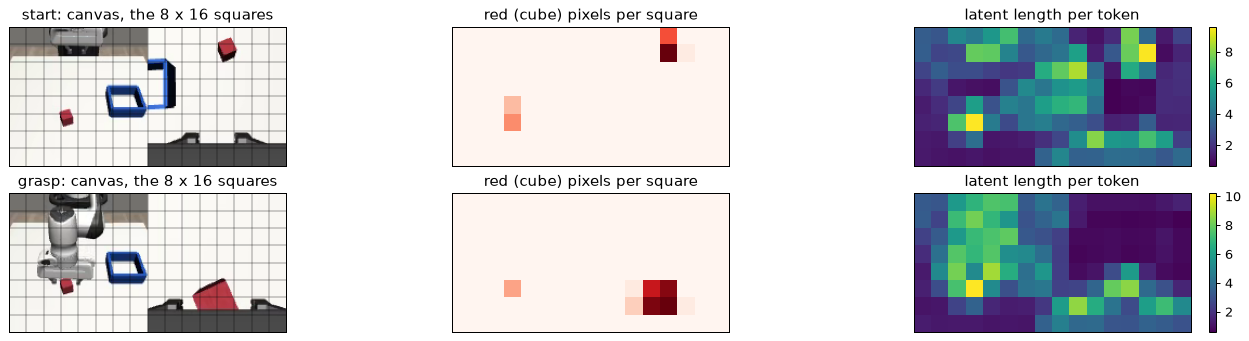

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(18, 4.4))
for r, name in enumerate(moments):
    axs[r, 0].imshow((x[r].permute(1, 2, 0).cpu() + 1) / 2)
    for k in range(1, 16):
        axs[r, 0].axvline(16 * k - 0.5, color='k', lw=0.3)
    for k in range(1, 8):
        axs[r, 0].axhline(16 * k - 0.5, color='k', lw=0.3)
    axs[r, 0].set_title(f'{name}: canvas, the 8 x 16 squares')
    axs[r, 1].imshow(cube_pixels(x[r]), cmap='Reds')
    axs[r, 1].set_title('red (cube) pixels per square')
    im = axs[r, 2].imshow(token_len[r], cmap='viridis')
    axs[r, 2].set_title('latent length per token')
    plt.colorbar(im, ax=axs[r, 2], fraction=0.025)
for ax in axs.flat:
    ax.set_xticks([])
    ax.set_yticks([])

**The cube's tokens are among the longest in the grid; blank table tokens are the shortest.** At the start the cube covers 4 squares (2 in each camera) and they rank 0, 4, 5 and 17 of 128 by length (median token 3.1, cube tokens 5.7-9.6); the single longest token of the whole canvas is a cube square. At the grasp the top camera's cube square is again the longest (rank 0); the wrist's big cube, 5 squares of mostly flat red, ranks 3 to 69: its edges are long, its uniform middle shorter. The bin, the arm and the wrist view's gripper base are long too.

In step 02 the same squares arrived as 768 pixel values, mostly the white of the table, and the video transformer had to find the cube in them itself. Here the VAE has already put the cube in a short list of loud tokens. That fits step 03's result (every seed finds the cube), but loud isn't proven to be the reason; section 4 looks at what the policy attends to.


### 3. the rollout path: a live canvas through the frozen VAE

The policy trained on stored latents: the demos' frames were saved as video (lossy), decoded, then encoded once. At rollout `frame_of(obs, vae)` (`data.py`) encodes the sim's own render instead, every replan. Do the two agree? Demo 82 was recorded from sim seed 82 (`recording_summary.json`), so resetting the sim with that seed redraws its first scene.

In [ ]:
import json

from dream_robot.policies.verne.data import REPO, frame_of

summary = json.loads((REPO / f'data/robosuite/{NAME}/recording_summary.json').read_text())
env = rollouts.make_env(wide=True)
obs = env.reset(seed=summary['episodes'][ep]['seed'])
live_px = np.concatenate([obs.images['top'], obs.images['wrist']], 1)  # [128, 256, 3] uint8
live_z = frame_of(obs, enc)[0].cpu().numpy()  # [4, 16, 32], what the policy reads at rollout
stored_px = canvas(cams['top'][rows[0]], cams['wrist'][rows[0]]).transpose(1, 2, 0)
stored_z = data['latent'][rows[0]].astype(np.float32)  # what it trained on

In [ ]:
px = np.abs(live_px.astype(int) - stored_px.astype(int))
print(f'pixels, live vs stored: mean |diff| {px.mean():.2f} of 255, max {px.max()}')
rms = lambda a, b: float(np.sqrt(((a - b) ** 2).mean()))
print(f'latent, live vs stored:         rms {rms(live_z, stored_z):.3f}')
print(
    f'latent, demo frame 0 vs 1:      rms {rms(stored_z, data["latent"][rows[1]].astype(np.float32)):.3f}'
)
print(
    f'latent, demo frame 0 vs 10:     rms {rms(stored_z, data["latent"][rows[10]].astype(np.float32)):.3f}'
)
print('latent std per channel: 1 (normalised)')

pixels, live vs stored: mean |diff| 1.60 of 255, max 79
latent, live vs stored:         rms 0.057
latent, demo frame 0 vs 1:      rms 0.000
latent, demo frame 0 vs 10:     rms 1.040
latent std per channel: 1 (normalised)


**Live and stored agree: the latents differ by rms 0.057, against 1.04 between the demo's frame 0 and frame 10** (frames 0 and 1 are identical: the arm hasn't moved yet). The pixels differ by 1.6 of 255 on average, up to 79 at a few edges, where the video compression smudged them; the VAE's 8 × 8 summaries average most of that away. So the policy reads at rollout what it trained on, to about 5% of one 10-step move. Not a gap worth worrying about here; on a real camera (other lighting, noise) it would be the first thing to measure.

### 4. the hands: where the action tokens look

As in `01_canvas_explained.ipynb` section 4: at each action layer, 16 action queries against 129 video keys + their own 16 = 145 keys; each layer's attention weight summed over groups: the joints token, the top camera's 64 tokens, the wrist's 64, the action tokens' own 16. New column `cube`: the tokens whose square holds a piece of the cube (section 2), a subset of top + wrist. Averaged over heads, the 16 queries, and 32 noise draws at τ = 0.9 (nearly clean), both moments.

Not the same comparison as step 01's table: that model was trained on T1 (cube within ±3 cm), this one on T1-wide (it has to find the cube).

In [ ]:
from einops import einsum

train_rows = np.isin(data['episode'], split_ids['train'])
a_mean = torch.tensor(data['action'][train_rows].mean(0)).cuda()
a_std = torch.tensor(data['action'][train_rows].std(0, ddof=1)).cuda()
col = np.arange(128) % 16  # token column: 0-7 top, 8-15 wrist


@torch.no_grad()
def attention_split(
    r: int, tau: float = 0.9, draws: int = 32
) -> tuple[list[str], np.ndarray, np.ndarray]:
    # moment r -> group names, [layers, groups] the action queries' attention weight on each, even shares
    i = idx[r]
    cube = np.flatnonzero(cube_pixels(x[r]).ravel() > 20)  # tokens holding the cube
    groups = {
        'joints': [0],
        'top': list(1 + np.flatnonzero(col < 8)),
        'wrist': list(1 + np.flatnonzero(col >= 8)),
        'cube': list(1 + cube),
        'own': list(range(129, 145)),
    }
    acts = torch.tensor(data['action'][np.minimum(i + np.arange(16), rows[-1])]).cuda()
    acts = (acts - a_mean) / a_std
    torch.manual_seed(0)
    noise = torch.randn(draws, 16, 8, device='cuda')
    xt = (1 - tau) * noise + tau * acts[None]
    t = torch.full((draws,), tau, device='cuda')
    y = net.action_in(xt) + net.action_pos + net.time_in(t[:, None])[:, None]
    kvs = net.see(z[r][None].expand(draws, -1, -1, -1), s[r][None].expand(draws, -1))
    out = []
    for block, (kv, vv) in zip(net.action, kvs):
        q, k, v = block.qkv_of(y)
        keys = torch.cat([kv, k], 2)  # [draws, heads, 145, 32]
        w = (einsum(q, keys, 'b h s d, b h t d -> b h s t') / keys.shape[-1] ** 0.5).softmax(-1)
        out.append([w[..., g].sum(-1).mean().item() for g in groups.values()])
        y = block.finish(y, q, keys, torch.cat([vv, v], 2))
    return list(groups), np.array(out), np.array([len(g) for g in groups.values()]) / 145

In [ ]:
for r, name in enumerate(moments):
    names, split_w, even = attention_split(r)
    print(f'{name:14s}' + ''.join(f'{g:>8s}' for g in names))
    print(f'{"even (n/145)":14s}' + ''.join(f'{e:8.2f}' for e in even))
    for n, row in enumerate(split_w):
        print(f'{name:5s} layer {n}  ' + ''.join(f'{w:8.2f}' for w in row))
    print()

start           joints     top   wrist    cube     own
even (n/145)      0.01    0.44    0.44    0.03    0.11
start layer 0      0.18    0.30    0.37    0.05    0.15
start layer 1      0.06    0.33    0.36    0.02    0.26
start layer 2      0.25    0.07    0.14    0.02    0.53
start layer 3      0.50    0.05    0.04    0.00    0.41

grasp           joints     top   wrist    cube     own
even (n/145)      0.01    0.44    0.44    0.04    0.11
grasp layer 0      0.25    0.34    0.25    0.07    0.16
grasp layer 1      0.14    0.33    0.40    0.05    0.13
grasp layer 2      0.45    0.14    0.11    0.02    0.30
grasp layer 3      0.66    0.05    0.04    0.01    0.25



**The action tokens don't look at the cube's tokens: the cube column stays at or below its even share in every layer (0.00-0.07, even 0.03-0.04).** One demo, two moments, training seed 0; attention weight is not influence.
- Layers 0-1: spread over both cameras near their even shares (top 0.30-0.34, wrist 0.25-0.40).
- Layers 2-3: the joints token (1 of 145) takes 0.25-0.66, and the action tokens' own 16 most of the rest; both cameras drop to ≤ 0.14.
- Yet every seed finds the cube (probe slope ≈ 1). So the cube's position must reach the action side some other way: the video tokens mix with each other through 4 layers of self-attention, so by layer 1 a token anywhere on the canvas can carry where the cube is. Reading the action side's attention by where a token sits on the canvas stops working past layer 0.
- Step 01's T1 model had the same shape (joints 0.33-0.44 in layers 1-3), and there it didn't find the cube. The difference isn't in where the action side looks; it's in what the video tokens carry. Checking that means probing the video tokens themselves (e.g. can a linear map read the cube's xy from each layer's tokens), not their attention.

### 5. probe: can the cube's xy be read off the video tokens?

Section 4 says the action side doesn't look at the cube's tokens, so the cube's position must travel inside the video tokens. Test: a linear map (ridge regression) from a layer's tokens to the cube's xy on the table. Two readouts per layer: the joints token, and the mean of the 128 patch tokens. Layer `in` = the tokens entering the video transformer, `0`-`3` = after each block.

Same probe on step 02's pixel model (`02_cosine_lr`, T1-wide seed 0, the one seed of step 02 that found the cube): its weights load into this model with `patch_in` back to 768 inputs, and it reads 16 × 16 pixel patches.

Frames: the sim's first frame for 1,000 seeds (T1-wide spawns), the arm at home in every one (the sim adds a small random jitter to the home pose, unrelated to the cube), so only the cube carries the answer. A first try used the demos' frames before the grasp, but there the arm is already heading to the cube and the joints alone gave the cube away to 2.5 cm (`scratch/probe_leak.py`); at step 0 the joints know nothing. Fit on seeds 0-799, score on 800-999.

In [ ]:
seeds = range(1000)
shots = []  # (canvas uint8 [3, 128, 256], joints [8], cube xy [2]) per seed
for seed in seeds:
    o = env.reset(seed=seed)
    top, wrist = (o.images[k].transpose(2, 0, 1) for k in ('top', 'wrist'))
    shots.append((canvas(top, wrist), o.state, env.cube_pos[:2].copy()))
px_all = np.stack([c for c, _, _ in shots])  # [1000, 3, 128, 256]
target = np.stack([xy for _, _, xy in shots])  # [1000, 2] m
is_val = np.arange(len(shots)) >= 800
st_all = (np.stack([j for _, j, _ in shots]) - data['state'][train_rows].mean(0)) / data['state'][
    train_rows
].std(0, ddof=1)
joints = np.stack([j for _, j, _ in shots])
print(
    f'{len(shots)} first frames, home pose jitter up to {np.ptp(joints[:, :7], 0).max():.2f} rad (random at reset, not tied to the cube); cube x {target[:, 0].min():+.2f}..{target[:, 0].max():+.2f} m, y {target[:, 1].min():+.2f}..{target[:, 1].max():+.2f} m'
)

1000 first frames, home pose jitter up to 0.14 rad (random at reset, not tied to the cube); cube x -0.10..+0.10 m, y -0.10..+0.06 m


In [ ]:
from einops import rearrange
from torch import nn

net02 = type(net)().cuda().eval()
net02.patch_in = nn.Linear(3 * 16 * 16, 256).cuda()  # step 02 read 16 x 16 pixel patches
net02.load_state_dict(torch.load(RUNS / '02_cosine_lr/t1-wide/seed0/weights.pt'))
s_all = (data['state'] - data['state'][train_rows].mean(0)) / data['state'][train_rows].std(
    0, ddof=1
)


@torch.no_grad()
def readouts(model, first) -> np.ndarray:
    # first: tokens [B, 128, 16 or 768] for the patches; -> [5 layers, 2 readouts, B, 256]
    x = torch.cat([model.state_in(st)[:, None], model.patch_in(first)], 1) + model.video_pos
    out = [x]
    for block in model.video:
        q, k, v = block.qkv_of(x)
        x = block.finish(x, q, k, v)
        out.append(x)
    return np.stack([[h[:, 0].cpu().numpy(), h[:, 1:].mean(1).cpu().numpy()] for h in out])


feats = {'02 pixels': [], '03 latents': []}
for b in np.array_split(np.arange(len(shots)), 8):
    st = torch.tensor(st_all[b], dtype=torch.float32).cuda()
    px = torch.tensor(px_all[b]).cuda().float() / 127.5 - 1
    zl = enc.encode(px)  # the live canvas through the frozen VAE, as at rollout
    feats['03 latents'].append(
        readouts(net, rearrange(zl, 'b c (h p) (w q) -> b (h w) (p q c)', p=2, q=2))
    )
    feats['02 pixels'].append(
        readouts(net02, rearrange(px, 'b c (h p) (w q) -> b (h w) (p q c)', p=16, q=16))
    )
feats = {k: np.concatenate(v, 2) for k, v in feats.items()}  # [5, 2, 1000, 256]
print({k: v.shape for k, v in feats.items()})

{'02 pixels': (5, 2, 1000, 256), '03 latents': (5, 2, 1000, 256)}


The probe, per layer and readout: ridge regression on standardised features, xy in cm.

```-
w = argmin_w  ‖F w − y‖² + λ ‖w‖²   →   w = (FᵀF + λI)⁻¹ Fᵀ y
```

λ = 1e-2 · n (n training frames) keeps 256 weights from fitting noise in 800 frames.

In [ ]:
def probe_cm(F: np.ndarray) -> float:
    # F [n, 256] -> mean distance (cm) between predicted and true cube xy on held-out seeds
    mu, sd = F[~is_val].mean(0), F[~is_val].std(0) + 1e-6
    A = np.c_[(F - mu) / sd, np.ones(len(F))]
    tr = ~is_val
    w = np.linalg.solve(
        A[tr].T @ A[tr] + 1e-2 * tr.sum() * np.eye(A.shape[1]), A[tr].T @ target[tr]
    )
    return float(np.linalg.norm(A[is_val] @ w - target[is_val], axis=1).mean() * 100)


print(
    f'guess the mean spot: {np.linalg.norm(target[is_val] - target[~is_val].mean(0), axis=1).mean() * 100:.1f} cm'
)
print(
    f'{"layer":7s}' + ''.join(f'{k + " " + r:>22s}' for k in feats for r in ('joints', 'patches'))
)
for n, layer in enumerate(['in', '0', '1', '2', '3']):
    print(
        f'{layer:7s}' + ''.join(f'{probe_cm(feats[k][n, r]):22.1f}' for k in feats for r in (0, 1))
    )

guess the mean spot: 7.1 cm
layer        02 pixels joints     02 pixels patches     03 latents joints    03 latents patches
in                        7.1                   7.0                   7.1                   6.3
0                         6.2                   5.8                   1.4                   1.9
1                         6.2                   5.2                   1.3                   1.7
2                         6.2                   5.1                   1.2                   1.4
3                         6.2                   5.0                   1.2                   1.4


**The latent model carries the cube's position in its video tokens from layer 0 on; the pixel model barely does.** Held-out seeds, mean distance between predicted and true cube xy (guessing the mean spot: 7.1 cm):

```-
                 joints token        mean of patch tokens
layer          02 pixels  03 latents   02 pixels  03 latents
in                7.1        7.1          7.0        6.3
0                 6.2        1.4          5.8        1.9
1-3               6.2        1.2-1.3      5.0-5.2    1.4-1.7
```

- At the input nothing is linear yet: the joints token knows nothing (7.1 = the mean guess), and the average patch token barely more (latents 6.3, pixels 7.0).
- One video layer later the latent model's joints token reads the cube to 1.4 cm: layer 0's attention has pulled the cube's position into it. The pixel model's joints token stays at 6.2 cm through all 4 layers; its patch tokens get to 5.0 cm.
- That's the step 03 result from the inside: the cube's xy is in the token the action side attends to most (section 4: joints 0.25-0.66 in layers 2-3). In step 02's pixel model, even this seed (the one that found the cube, probe slope +0.73) holds it only weakly and not in that token.
- Caveats: one training seed per model, a linear readout (the pixel model may hold the position in a form a linear map can't read), first frames only.

### 6. wrap-up: what step 03 buys, and where it fails

**Buys:** the cube's position, early and in the right place. The frozen VAE turns the canvas into a 4 × 16 × 32 grid where the table is near 0 and the cube's squares are among the loudest tokens (section 2). From there one video layer is enough to put the cube's xy into the joints token (section 5: 1.4 cm, against 6.2 cm for step 02's pixel model), and that is the token the action side reads most (section 4). Result: every training seed finds the cube on T1-wide, 112/150 at both n_exec (`03_vae_latents.ipynb`; step 02: 29 and 14). Also cheaper: 16 numbers per patch instead of 768, 90 MB of latents per dataset instead of 2.2 GB of frames, and at rollout the live canvas encodes to within 5% of a 10-step move of what training saw (section 3).

**Where it fails:**
- The reach is right, the grasp isn't always: most failures are still `no_grasp` (7-14 per seed).
- The action side never looks at the cube's own tokens (section 4); everything goes through the joints token. One summary token is a narrow channel: fine for one cube's xy, maybe not for its orientation or several objects.
- Our VAE was trained on these very frames. Verne's is Wan2.2's, pretrained on web video and never shown this table. Whether a general-purpose VAE puts the cube up front the same way is untested.
- One seed per model in sections 4-5, linear probes only, first frames only; T1 (10 demos) not run.

**Next box candidates** (`roadmap.md`): memory (03), time embedding + adaptive norm (04), or a look at the `no_grasp` failures, now that reaching works.